In [2]:
!pip install tensorflow numpy matplotlib

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ------ --------------------------------- 1.6/9.3 MB 13.9 MB/s eta 0:00:01
   -------------------- ------------------- 4.7/9.3 MB 11.9 MB/s eta 0:00:01
   -------------------------------- ------- 7.6/9.3 MB 12.4 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 12.3 MB/s  0:00:00
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ---------------------------------------- 1.7/1.7 MB 7.6 MB/s  0:00:00

   ---------------------------------------- 0/6 [pyparsing]
   ---------------------------------------- 0/6 [pyparsing]
   ---------------------------------------- 0/6 [pyparsing]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- -------------------------- 2


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.datasets import cifar10

tf.keras.utils.set_random_seed(42) #Used seeding for reproducibility

Matplotlib is building the font cache; this may take a moment.


In [4]:
(x_train, y_train), (x_test, y_test) = cifar10.load_data()
y_train, y_test = y_train.flatten(), y_test.flatten()
print(x_train.shape, y_train.shape, x_test.shape)

170498071/170498071 [==============================] - 2407s 14us/step
(50000, 32, 32, 3) (50000,) (10000, 32, 32, 3)


50,000 training images, each 32×32 pixels with 3 colour channels (red, green, blue), and 10,000 test images

Labels in CIFAR-10 are just numbers from 0 to 9. This list tells us which number means which object, and then we display a few images to check the data.

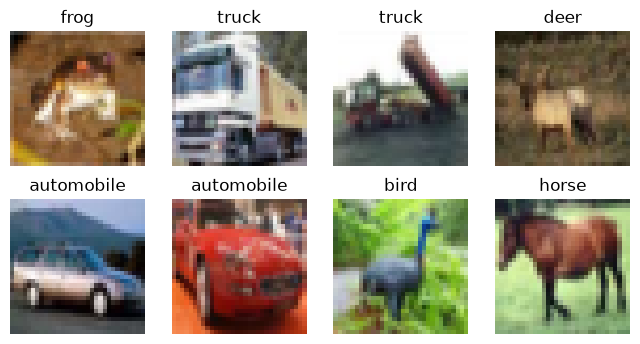

In [5]:
class_names = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]

plt.figure(figsize=(8, 4))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i]])
    plt.axis("off")
plt.show()

In [6]:
# Part 1: validation split
x_val, y_val = x_train[-5000:], y_train[-5000:]
x_train, y_train = x_train[:-5000], y_train[:-5000]

# Part 2: normalization
mean = (x_train / 255.0).mean(axis=(0, 1, 2))
std  = (x_train / 255.0).std(axis=(0, 1, 2))

def normalize(x):
    return (x / 255.0 - mean) / std

x_test_raw = x_test   # keep the original test images for plotting later
x_train, x_val, x_test = normalize(x_train), normalize(x_val), normalize(x_test)

print(x_train.shape, x_val.shape, x_test.shape)

(45000, 32, 32, 3) (5000, 32, 32, 3) (10000, 32, 32, 3)


In [7]:
BATCH = 128
AUTOTUNE = tf.data.AUTOTUNE

def augment(x, y):
    x = tf.image.random_flip_left_right(x)
    x = tf.image.resize_with_crop_or_pad(x, 40, 40)   # pad the image to 40x40
    x = tf.image.random_crop(x, [32, 32, 3])          # randomly crop back to 32x32
    return x, y

train_ds = (tf.data.Dataset.from_tensor_slices((x_train, y_train))
            .shuffle(10000)
            .map(augment, num_parallel_calls=AUTOTUNE)
            .batch(BATCH)
            .prefetch(AUTOTUNE))

val_ds  = tf.data.Dataset.from_tensor_slices((x_val, y_val)).batch(BATCH).prefetch(AUTOTUNE)
test_ds = tf.data.Dataset.from_tensor_slices((x_test, y_test)).batch(BATCH).prefetch(AUTOTUNE)

In [8]:
for images, labels in train_ds.take(1):
    print(images.shape, labels.shape)

(128, 32, 32, 3) (128,)


In [9]:
def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    return layers.ReLU()(x)

inputs = layers.Input((32, 32, 3))
x = inputs
for filters in [32, 64, 128]:
    x = conv_block(x, filters)
    x = conv_block(x, filters)
    x = layers.MaxPooling2D()(x)
    x = layers.Dropout(0.3)(x)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(10, activation="softmax")(x)

baseline = models.Model(inputs, outputs)
baseline.summary()



Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 32, 32, 3)]       0         
                                                                 
 conv2d (Conv2D)             (None, 32, 32, 32)        864       
                                                                 
 batch_normalization (Batch  (None, 32, 32, 32)        128       
 Normalization)                                                  
                                                                 
 re_lu (ReLU)                (None, 32, 32, 32)        0         
                                                                 
 conv2d_1 (Conv2D)           (None, 32, 32, 32)        9216      
                                                                 
 batch_normalization_1 (Bat  (None, 32, 32, 32)        128       
 chNormalization)                                          

In [10]:
baseline.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                 loss="sparse_categorical_crossentropy",
                 metrics=["accuracy"])

In [11]:
cbs = [
    callbacks.ModelCheckpoint("baseline_best.keras", monitor="val_accuracy", save_best_only=True),
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, verbose=1),
]

history = baseline.fit(train_ds, validation_data=val_ds, epochs=30, callbacks=cbs)

Epoch 1/30


352/352 [==============================] - 135s 375ms/step - loss: 1.6028 - accuracy: 0.4146 - val_loss: 1.7288 - val_accuracy: 0.3996 - lr: 0.0010
Epoch 2/30
352/352 [==============================] - 142s 403ms/step - loss: 1.2192 - accuracy: 0.5644 - val_loss: 1.3631 - val_accuracy: 0.5360 - lr: 0.0010
Epoch 3/30
352/352 [==============================] - 142s 402ms/step - loss: 1.0765 - accuracy: 0.6171 - val_loss: 0.9303 - val_accuracy: 0.6644 - lr: 0.0010
Epoch 4/30
352/352 [==============================] - 141s 401ms/step - loss: 0.9939 - accuracy: 0.6479 - val_loss: 0.8138 - val_accuracy: 0.7132 - lr: 0.0010
Epoch 5/30
352/352 [==============================] - 135s 384ms/step - loss: 0.9186 - accuracy: 0.6782 - val_loss: 0.7802 - val_accuracy: 0.7330 - lr: 0.0010
Epoch 6/30
352/352 [==============================] - 132s 375ms/step - loss: 0.8578 - accuracy: 0.7011 - val_loss: 0.7616 - val_accuracy: 0.7230 - lr: 0.0010
Epoch 7/30
352/352 [========================

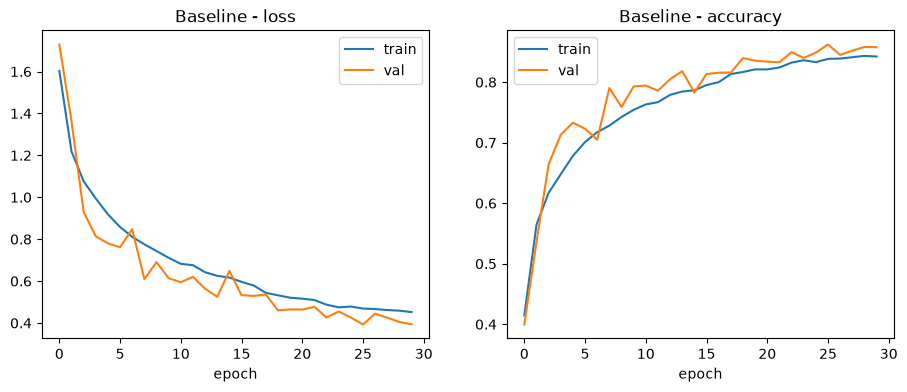

In [12]:
def plot_history(h, title):
    plt.figure(figsize=(11, 4))

    plt.subplot(1, 2, 1)
    plt.plot(h.history["loss"], label="train")
    plt.plot(h.history["val_loss"], label="val")
    plt.title(title + " - loss")
    plt.xlabel("epoch")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(h.history["accuracy"], label="train")
    plt.plot(h.history["val_accuracy"], label="val")
    plt.title(title + " - accuracy")
    plt.xlabel("epoch")
    plt.legend()

    plt.show()

plot_history(history, "Baseline")

In [13]:
best_baseline = tf.keras.models.load_model("baseline_best.keras")
test_loss, test_acc = best_baseline.evaluate(test_ds)
print("Baseline test accuracy:", test_acc)

79/79 [==============================] - 3s 35ms/step - loss: 0.4227 - accuracy: 0.8558
Baseline test accuracy: 0.8557999730110168


79/79 [==============================] - 3s 32ms/step


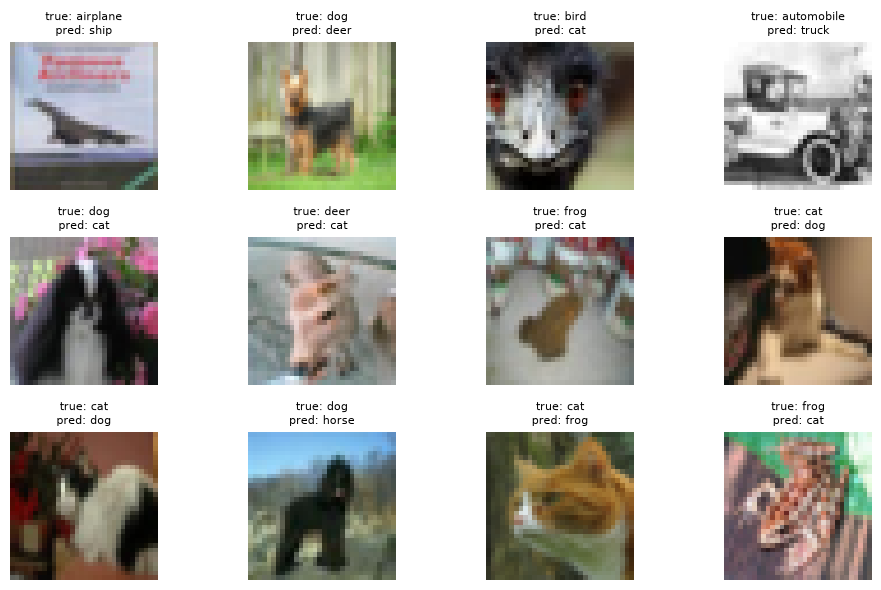

In [14]:
preds = best_baseline.predict(test_ds).argmax(axis=1)
wrong = np.where(preds != y_test)[0][:12]

plt.figure(figsize=(10, 6))
for n, i in enumerate(wrong):
    plt.subplot(3, 4, n + 1)
    plt.imshow(x_test_raw[i])
    plt.title(f"true: {class_names[y_test[i]]}\npred: {class_names[preds[i]]}", fontsize=8)
    plt.axis("off")
plt.tight_layout()
plt.show()

In [15]:
def make_datasets(batch_size):
    train = (tf.data.Dataset.from_tensor_slices((x_train, y_train))
             .shuffle(10000)
             .map(augment, num_parallel_calls=AUTOTUNE)
             .batch(batch_size).prefetch(AUTOTUNE))
    val  = tf.data.Dataset.from_tensor_slices((x_val, y_val)).batch(batch_size).prefetch(AUTOTUNE)
    test = tf.data.Dataset.from_tensor_slices((x_test, y_test)).batch(batch_size).prefetch(AUTOTUNE)
    return train, val, test


def build_model(dropout=0.3):
    inputs = layers.Input((32, 32, 3))
    x = inputs
    for filters in [32, 64, 128]:
        x = conv_block(x, filters)
        x = conv_block(x, filters)
        x = layers.MaxPooling2D()(x)
        x = layers.Dropout(dropout)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(10, activation="softmax")(x)
    return models.Model(inputs, outputs)


print(build_model().count_params())

289642


In [16]:
results = {}   # stores the score of every experiment

def run_experiment(name, lr=1e-3, batch_size=128, optimizer="adam", dropout=0.3, epochs=5):
    tf.keras.backend.clear_session()        # free memory from the previous model
    tf.keras.utils.set_random_seed(42)      # same seed every run, so the comparison is fair

    train_d, val_d, _ = make_datasets(batch_size)
    model = build_model(dropout)

    optimizers = {
        "adam":    tf.keras.optimizers.Adam(lr),
        "sgd":     tf.keras.optimizers.SGD(lr, momentum=0.9),
        "rmsprop": tf.keras.optimizers.RMSprop(lr),
    }
    model.compile(optimizer=optimizers[optimizer],
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])

    model.fit(train_d, validation_data=val_d, epochs=epochs, verbose=2)

    _, val_acc = model.evaluate(val_d, verbose=0)
    results[name] = val_acc
    print(f">>> {name}: val_accuracy = {val_acc:.4f}")

In [17]:
run_experiment("baseline (lr=1e-3, bs=128, adam, drop=0.3)")

Epoch 1/5
352/352 - 117s - loss: 1.6085 - accuracy: 0.4114 - val_loss: 1.3326 - val_accuracy: 0.5044 - 117s/epoch - 332ms/step
Epoch 2/5
352/352 - 120s - loss: 1.2079 - accuracy: 0.5683 - val_loss: 1.2507 - val_accuracy: 0.5642 - 120s/epoch - 342ms/step
Epoch 3/5
352/352 - 115s - loss: 1.0717 - accuracy: 0.6179 - val_loss: 0.9632 - val_accuracy: 0.6620 - 115s/epoch - 326ms/step
Epoch 4/5
352/352 - 101s - loss: 0.9794 - accuracy: 0.6539 - val_loss: 1.0285 - val_accuracy: 0.6476 - 101s/epoch - 287ms/step
Epoch 5/5
352/352 - 115s - loss: 0.9122 - accuracy: 0.6801 - val_loss: 0.9019 - val_accuracy: 0.6846 - 115s/epoch - 328ms/step
>>> baseline (lr=1e-3, bs=128, adam, drop=0.3): val_accuracy = 0.6846


In [18]:
run_experiment("lr=1e-2", lr=1e-2)
run_experiment("lr=1e-4", lr=1e-4)

Epoch 1/5
352/352 - 114s - loss: 1.6277 - accuracy: 0.3964 - val_loss: 1.5183 - val_accuracy: 0.4818 - 114s/epoch - 324ms/step
Epoch 2/5
352/352 - 119s - loss: 1.2002 - accuracy: 0.5702 - val_loss: 1.6373 - val_accuracy: 0.4960 - 119s/epoch - 338ms/step
Epoch 3/5
352/352 - 106s - loss: 1.0364 - accuracy: 0.6340 - val_loss: 1.1874 - val_accuracy: 0.5942 - 106s/epoch - 301ms/step
Epoch 4/5
352/352 - 101s - loss: 0.9364 - accuracy: 0.6704 - val_loss: 0.9155 - val_accuracy: 0.6864 - 101s/epoch - 286ms/step
Epoch 5/5
352/352 - 104s - loss: 0.8589 - accuracy: 0.6997 - val_loss: 1.0614 - val_accuracy: 0.6420 - 104s/epoch - 295ms/step
>>> lr=1e-2: val_accuracy = 0.6420
Epoch 1/5
352/352 - 102s - loss: 2.0737 - accuracy: 0.2648 - val_loss: 2.3138 - val_accuracy: 0.2106 - 102s/epoch - 291ms/step
Epoch 2/5
352/352 - 92s - loss: 1.6824 - accuracy: 0.3768 - val_loss: 1.6613 - val_accuracy: 0.4074 - 92s/epoch - 262ms/step
Epoch 3/5
352/352 - 94s - loss: 1.5315 - accuracy: 0.4408 - val_loss: 1.5178 -

In [19]:
run_experiment("bs=64", batch_size=64)
run_experiment("bs=256", batch_size=256)

Epoch 1/5
704/704 - 97s - loss: 1.5422 - accuracy: 0.4419 - val_loss: 1.3950 - val_accuracy: 0.5172 - 97s/epoch - 138ms/step
Epoch 2/5
704/704 - 103s - loss: 1.1741 - accuracy: 0.5841 - val_loss: 1.1285 - val_accuracy: 0.6082 - 103s/epoch - 146ms/step
Epoch 3/5
704/704 - 118s - loss: 1.0361 - accuracy: 0.6321 - val_loss: 0.8605 - val_accuracy: 0.6960 - 118s/epoch - 168ms/step
Epoch 4/5
704/704 - 110s - loss: 0.9471 - accuracy: 0.6670 - val_loss: 1.0663 - val_accuracy: 0.6528 - 110s/epoch - 156ms/step
Epoch 5/5
704/704 - 101s - loss: 0.8692 - accuracy: 0.6973 - val_loss: 0.8267 - val_accuracy: 0.7128 - 101s/epoch - 144ms/step
>>> bs=64: val_accuracy = 0.7128
Epoch 1/5
176/176 - 102s - loss: 1.7049 - accuracy: 0.3729 - val_loss: 2.4608 - val_accuracy: 0.2108 - 102s/epoch - 577ms/step
Epoch 2/5
176/176 - 104s - loss: 1.2873 - accuracy: 0.5350 - val_loss: 1.3747 - val_accuracy: 0.5116 - 104s/epoch - 589ms/step
Epoch 3/5
176/176 - 107s - loss: 1.1332 - accuracy: 0.5937 - val_loss: 1.1122 - 

In [20]:
run_experiment("sgd (lr=1e-2)", optimizer="sgd", lr=1e-2)
run_experiment("rmsprop (lr=1e-3)", optimizer="rmsprop", lr=1e-3)

Epoch 1/5
352/352 - 85s - loss: 1.7614 - accuracy: 0.3458 - val_loss: 1.4835 - val_accuracy: 0.4528 - 85s/epoch - 241ms/step
Epoch 2/5
352/352 - 96s - loss: 1.4006 - accuracy: 0.4890 - val_loss: 1.4602 - val_accuracy: 0.4754 - 96s/epoch - 272ms/step
Epoch 3/5
352/352 - 68s - loss: 1.2474 - accuracy: 0.5471 - val_loss: 1.3869 - val_accuracy: 0.5244 - 68s/epoch - 194ms/step
Epoch 4/5
352/352 - 72s - loss: 1.1543 - accuracy: 0.5863 - val_loss: 1.0561 - val_accuracy: 0.6192 - 72s/epoch - 205ms/step
Epoch 5/5
352/352 - 78s - loss: 1.0910 - accuracy: 0.6097 - val_loss: 1.0471 - val_accuracy: 0.6158 - 78s/epoch - 220ms/step
>>> sgd (lr=1e-2): val_accuracy = 0.6158
Epoch 1/5
352/352 - 71s - loss: 1.5936 - accuracy: 0.4206 - val_loss: 1.4270 - val_accuracy: 0.4836 - 71s/epoch - 203ms/step
Epoch 2/5
352/352 - 70s - loss: 1.2096 - accuracy: 0.5675 - val_loss: 1.2459 - val_accuracy: 0.5752 - 70s/epoch - 199ms/step
Epoch 3/5
352/352 - 69s - loss: 1.0742 - accuracy: 0.6187 - val_loss: 1.1757 - val_a

In [21]:
run_experiment("dropout=0.1", dropout=0.1)
run_experiment("dropout=0.5", dropout=0.5)

Epoch 1/5
352/352 - 70s - loss: 1.3797 - accuracy: 0.4995 - val_loss: 1.3257 - val_accuracy: 0.5322 - 70s/epoch - 199ms/step
Epoch 2/5
352/352 - 72s - loss: 1.0278 - accuracy: 0.6350 - val_loss: 0.9289 - val_accuracy: 0.6746 - 72s/epoch - 206ms/step
Epoch 3/5
352/352 - 71s - loss: 0.8858 - accuracy: 0.6886 - val_loss: 0.8192 - val_accuracy: 0.7126 - 71s/epoch - 203ms/step
Epoch 4/5
352/352 - 70s - loss: 0.7884 - accuracy: 0.7249 - val_loss: 1.0814 - val_accuracy: 0.6488 - 70s/epoch - 200ms/step
Epoch 5/5
352/352 - 71s - loss: 0.7233 - accuracy: 0.7486 - val_loss: 0.7311 - val_accuracy: 0.7456 - 71s/epoch - 202ms/step
>>> dropout=0.1: val_accuracy = 0.7456
Epoch 1/5
352/352 - 72s - loss: 1.8907 - accuracy: 0.3092 - val_loss: 1.6008 - val_accuracy: 0.4082 - 72s/epoch - 205ms/step
Epoch 2/5
352/352 - 75s - loss: 1.4674 - accuracy: 0.4634 - val_loss: 1.2558 - val_accuracy: 0.5418 - 75s/epoch - 214ms/step
Epoch 3/5
352/352 - 80s - loss: 1.2976 - accuracy: 0.5336 - val_loss: 1.1209 - val_acc

In [22]:
print(f"{'Experiment':50s} Val accuracy")
print("-" * 65)
for name, acc in sorted(results.items(), key=lambda item: item[1], reverse=True):
    print(f"{name:50s} {acc:.4f}")

Experiment                                         Val accuracy
-----------------------------------------------------------------
dropout=0.1                                        0.7456
bs=64                                              0.7128
baseline (lr=1e-3, bs=128, adam, drop=0.3)         0.6846
rmsprop (lr=1e-3)                                  0.6644
bs=256                                             0.6434
lr=1e-2                                            0.6420
dropout=0.5                                        0.6354
sgd (lr=1e-2)                                      0.6158
lr=1e-4                                            0.4986


Final model with best settings

In [23]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

train_t, val_t, test_t = make_datasets(64)          # best batch size
tuned = build_model(dropout=0.1)                    # best dropout

tuned.compile(optimizer=tf.keras.optimizers.Adam(1e-3),   # best optimizer + learning rate
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

cbs_t = [
    callbacks.ModelCheckpoint("tuned_best.keras", monitor="val_accuracy", save_best_only=True),
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, verbose=1),
]

history_t = tuned.fit(train_t, validation_data=val_t, epochs=30, callbacks=cbs_t)

Epoch 1/30
704/704 [==============================] - 67s 94ms/step - loss: 1.3527 - accuracy: 0.5098 - val_loss: 1.3046 - val_accuracy: 0.5674 - lr: 0.0010
Epoch 2/30
704/704 [==============================] - 76s 108ms/step - loss: 1.0083 - accuracy: 0.6428 - val_loss: 1.2048 - val_accuracy: 0.5962 - lr: 0.0010
Epoch 3/30
704/704 [==============================] - 82s 116ms/step - loss: 0.8657 - accuracy: 0.6941 - val_loss: 0.8932 - val_accuracy: 0.6784 - lr: 0.0010
Epoch 4/30
704/704 [==============================] - 86s 122ms/step - loss: 0.7699 - accuracy: 0.7304 - val_loss: 1.2037 - val_accuracy: 0.6538 - lr: 0.0010
Epoch 5/30
704/704 [==============================] - 91s 130ms/step - loss: 0.7014 - accuracy: 0.7557 - val_loss: 0.8039 - val_accuracy: 0.7176 - lr: 0.0010
Epoch 6/30
704/704 [==============================] - 90s 128ms/step - loss: 0.6527 - accuracy: 0.7738 - val_loss: 0.7951 - val_accuracy: 0.7250 - lr: 0.0010
Epoch 7/30
704/704 [==============================] -

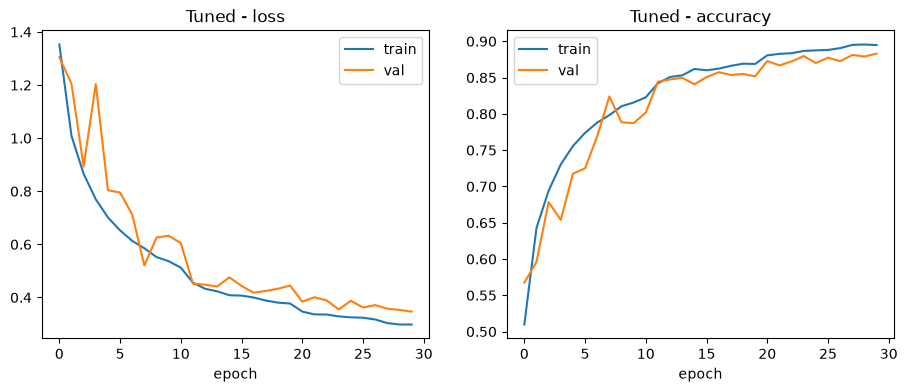

In [24]:
plot_history(history_t, "Tuned")

In [25]:
best_tuned = tf.keras.models.load_model("tuned_best.keras")
tuned_loss, tuned_acc = best_tuned.evaluate(test_t)

print(f"Baseline test accuracy: {test_acc:.4f}")
print(f"Tuned test accuracy:    {tuned_acc:.4f}")
print(f"Improvement:            {(tuned_acc - test_acc) * 100:.2f} points")

157/157 [==============================] - 3s 17ms/step - loss: 0.3815 - accuracy: 0.8753
Baseline test accuracy: 0.8558
Tuned test accuracy:    0.8753
Improvement:            1.95 points


In [ ]:
print(f"{'Model':10s}{'Batch':>7}{'Dropout':>9}{'Optimizer':>11}{'LR':>7}{'Test acc':>10}")
print(f"{'Baseline':10s}{128:>7}{0.3:>9}{'Adam':>11}{'1e-3':>7}{test_acc:>10.4f}")
print(f"{'Tuned':10s}{64:>7}{0.1:>9}{'Adam':>11}{'1e-3':>7}{tuned_acc:>10.4f}")

Model       Batch  Dropout  Optimizer     LR  Test acc
Baseline      128      0.3       Adam   1e-3    0.8558
Tuned          64      0.1       Adam   1e-3    0.8753


: 